# E2 (RQ2). Which phenotypes are specific to a space and which ones are transversal?

## Context dependence measure

Let $s$ be a phenotype with description $d = d_P \wedge d_C$, where $d_P$ contains the patient selectors and $d_C$ the context selectors, and let $U$ be the set of units. For each unit $u \in U$ in which $d_P$ covers at least $m = 10$ instances, $OR_u(d_P)$ is the odds ratio between being covered by $d_P$ and being resistant, computed only with the instances of $u$ (Haldane correction when a cell is 0). With the $k$ units in which $d_P$ is observed:

- Degree of context dependence: $CD(s) = I^2 = \max\left(0, \frac{Q - (k-1)}{Q}\right) \in [0, 1]$, where $Q = \sum_u w_u (\log OR_u - \overline{\log OR})^2$ is Cochran's heterogeneity statistic with inverse-variance weights $w_u$. $CD(s) = 0$: the effect of the patient profile is the same in every unit; $CD(s) \to 1$: the effect depends on the unit.
- Heterogeneity test: Breslow-Day test of homogeneity of $OR_u$; global effect: Mantel-Haenszel pooled odds ratio and its test. Both p-values are corrected with Benjamini-Hochberg over all the phenotypes.
- Active units: $A(s) = \{u \in U : \text{lower bound of the 95\% CI of } OR_u > 1\}$.
- Label:
  - SPACE_SPECIFIC: significant heterogeneity and $A(s)$ is a strict subset of the units where $s$ is observed (the profile only increases the risk in some spaces: local actions).
  - SPACE_MODULATED: significant heterogeneity, but $A(s)$ contains all the units where $s$ is observed (the profile increases the risk everywhere, with a different magnitude).
  - TRANSVERSAL: no significant heterogeneity and pooled OR significantly greater than 1 (hospital-wide actions).
  - NOT_ASSOCIATED otherwise; OBSERVED_IN_ONE_UNIT if $k = 1$; CONTEXT_ONLY if $d_P$ is empty.
  - CONTEXT_DRIVEN: $d_C$ is not empty and $d_P$ alone is NOT_ASSOCIATED or protective (the risk comes from the space, not from the patient profile).
- For the phenotypes with context selectors, the context gain is $WRAcc(d) - WRAcc(d_P)$ and the precision gain is $P(R \\mid d) - P(R \\mid d_P)$.

Implementation: `utils.context_dependence` and `utils.label_context_dependence`.

Inputs: the best subgroup lists of each configuration (DSLM output, `Experiments/phenotypes/results/clinical/mining/`). Outputs: `results/tables/` and `results/figures/`.

In [1]:
import sys
sys.path.insert(0, "..")
import utils
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
view = "clinical"
df = utils.read_mining_view(view)
# Best hyperparameters of each configuration (Experiments/phenotypes/results/clinical/best_models.csv).
best_models = pd.read_csv(utils.best_models_path(view)).set_index("configuration")

def best_subgroup_lists(configuration):
    # Output file of DSLM (subgroups library) with the best hyperparameters.
    return utils.read_subgroup_lists(utils.best_subgroup_lists_path(view, best_models, configuration))

TABLES_PATH = utils.results_path("E2-context-dependence", "tables")
FIGURES_PATH = utils.results_path("E2-context-dependence", "figures")
best_models

,beta,maximum_positive_overlap,maximum_negative_overlap,quality,coverage,diversity,number_of_subgroups
configuration,,,,,,,
without_context,0.75,0.6,0.6,0.126334,0.746108,0.738095,14
with_context,0.75,0.6,0.6,0.120226,0.694212,0.611111,16
unit_MICU,0.30,0.6,0.6,0.093467,0.879617,0.766667,5
unit_SICU,1.00,0.1,0.1,0.068543,0.503546,0.722222,4
unit_TSICU,0.00,0.1,0.1,0.025262,0.401674,1.000000,1
unit_CCU,0.00,0.1,0.1,0.022783,0.264423,1.000000,1
unit_CSRU,0.00,0.1,0.1,0.042283,0.468966,1.000000,1
unit_NO_ICU,0.00,0.1,0.1,0.055878,0.471673,1.000000,3


# 1. Phenotypes of all the configurations

In [3]:
records = []
for configuration in utils.CONFIGURATIONS:
    for index, subgroup_list in enumerate(best_subgroup_lists(configuration)):
        for position, description in enumerate(subgroup_list):
            records.append({"configuration" : configuration, "list" : index + 1, "position" : position + 1, "description" : description})
phenotypes = pd.DataFrame(records)
phenotypes.assign(description=phenotypes["description"].map(utils.description_to_str)).to_csv(TABLES_PATH / "phenotypes_of_all_the_configurations.csv", index=False)
print("Number of subgroups: " + str(len(phenotypes)))
print("Number of different descriptions: " + str(phenotypes["description"].nunique()))

Number of subgroups: 45
Number of different descriptions: 37


# 2. Context dependence of each phenotype

In [4]:
y = utils.get_target_mask(df)
results = []
for description, group in phenotypes.groupby("description", sort=False):
    result = utils.context_dependence(df, description)
    covered = utils.covers(df, description)
    result["configurations"] = ", ".join(sorted(group["configuration"].unique()))
    result["n_global"] = int(covered.sum())
    result["precision_global"] = y[covered].mean() if covered.sum() else np.nan
    results.append(result)
results = utils.label_context_dependence(pd.DataFrame(results))
results.to_csv(TABLES_PATH / "context_dependence.csv", index=False)
columns = ["description", "configurations", "n_global", "precision_global", "units_observed", "pooled_or", "i2", "p_heterogeneity_bh", "p_pooled_bh", "label", "active_units"]
results[columns].sort_values(["label", "i2"], ascending=[True, False]).round(3)

,description,configurations,n_global,precision_global,units_observed,pooled_or,i2,p_heterogeneity_bh,p_pooled_bh,label,active_units
19,[previous_exposure_to_third_generation_cephalo...,with_context,73,0.767,6,0.326,0.000,0.695,0.000,CONTEXT_DRIVEN,
24,[organ_transplant_in_previous_admissions = 'no...,with_context,74,0.757,6,0.371,0.000,0.846,0.000,CONTEXT_DRIVEN,
13,[organ_transplant_in_previous_admissions = 'no...,without_context,909,0.361,6,1.171,0.000,0.936,0.082,NOT_ASSOCIATED,
29,[patient_gender = 'F'],unit_MICU,1238,0.343,6,1.104,0.000,0.695,0.252,NOT_ASSOCIATED,
16,"[admission_type = 'EMERGENCY', service_when_cu...",with_context,213,0.629,6,5.268,0.700,0.032,0.000,SPACE_MODULATED,"MICU, SICU, TSICU, CCU, CSRU, NO_ICU"
14,"[service_when_culture = 'OMED', treated_with_v...",with_context,57,0.842,6,5.706,0.690,0.032,0.000,SPACE_MODULATED,"MICU, SICU, TSICU, CCU, CSRU, NO_ICU"
34,[treated_with_vancomycin_in_the_current_admiss...,"unit_CCU, unit_CSRU, unit_NO_ICU, unit_TSICU",1021,0.557,6,5.706,0.690,0.032,0.000,SPACE_MODULATED,"MICU, SICU, TSICU, CCU, CSRU, NO_ICU"
30,"[previous_isolation_of_sarm = 'no', treated_wi...",unit_MICU,998,0.556,6,5.418,0.684,0.032,0.000,SPACE_MODULATED,"MICU, SICU, TSICU, CCU, CSRU, NO_ICU"
28,[hematopoietic_transplant_in_previous_admissio...,unit_MICU,1020,0.557,6,5.678,0.679,0.032,0.000,SPACE_MODULATED,"MICU, SICU, TSICU, CCU, CSRU, NO_ICU"
27,[admission_location = 'REFERRAL'],with_context,763,0.374,6,1.335,0.710,0.032,0.002,SPACE_SPECIFIC,"SICU, NO_ICU"


In [5]:
labels_by_configuration = pd.crosstab(results["configurations"], results["label"])
labels_by_configuration.to_csv(TABLES_PATH / "labels_by_configuration.csv")
labels_by_configuration

label,CONTEXT_DRIVEN,NOT_ASSOCIATED,SPACE_MODULATED,SPACE_SPECIFIC,TRANSVERSAL
configurations,,,,,
"unit_CCU, unit_CSRU, unit_NO_ICU, unit_TSICU",0,0,1,0,0
unit_MICU,0,1,2,0,1
"unit_MICU, unit_SICU, with_context, without_context",0,0,0,0,1
unit_NO_ICU,0,0,0,0,2
unit_SICU,0,0,0,0,2
"unit_SICU, with_context",0,0,0,0,1
with_context,2,0,2,1,8
"with_context, without_context",0,0,0,0,1
without_context,0,1,0,3,8


# 3. Heatmap units x phenotypes

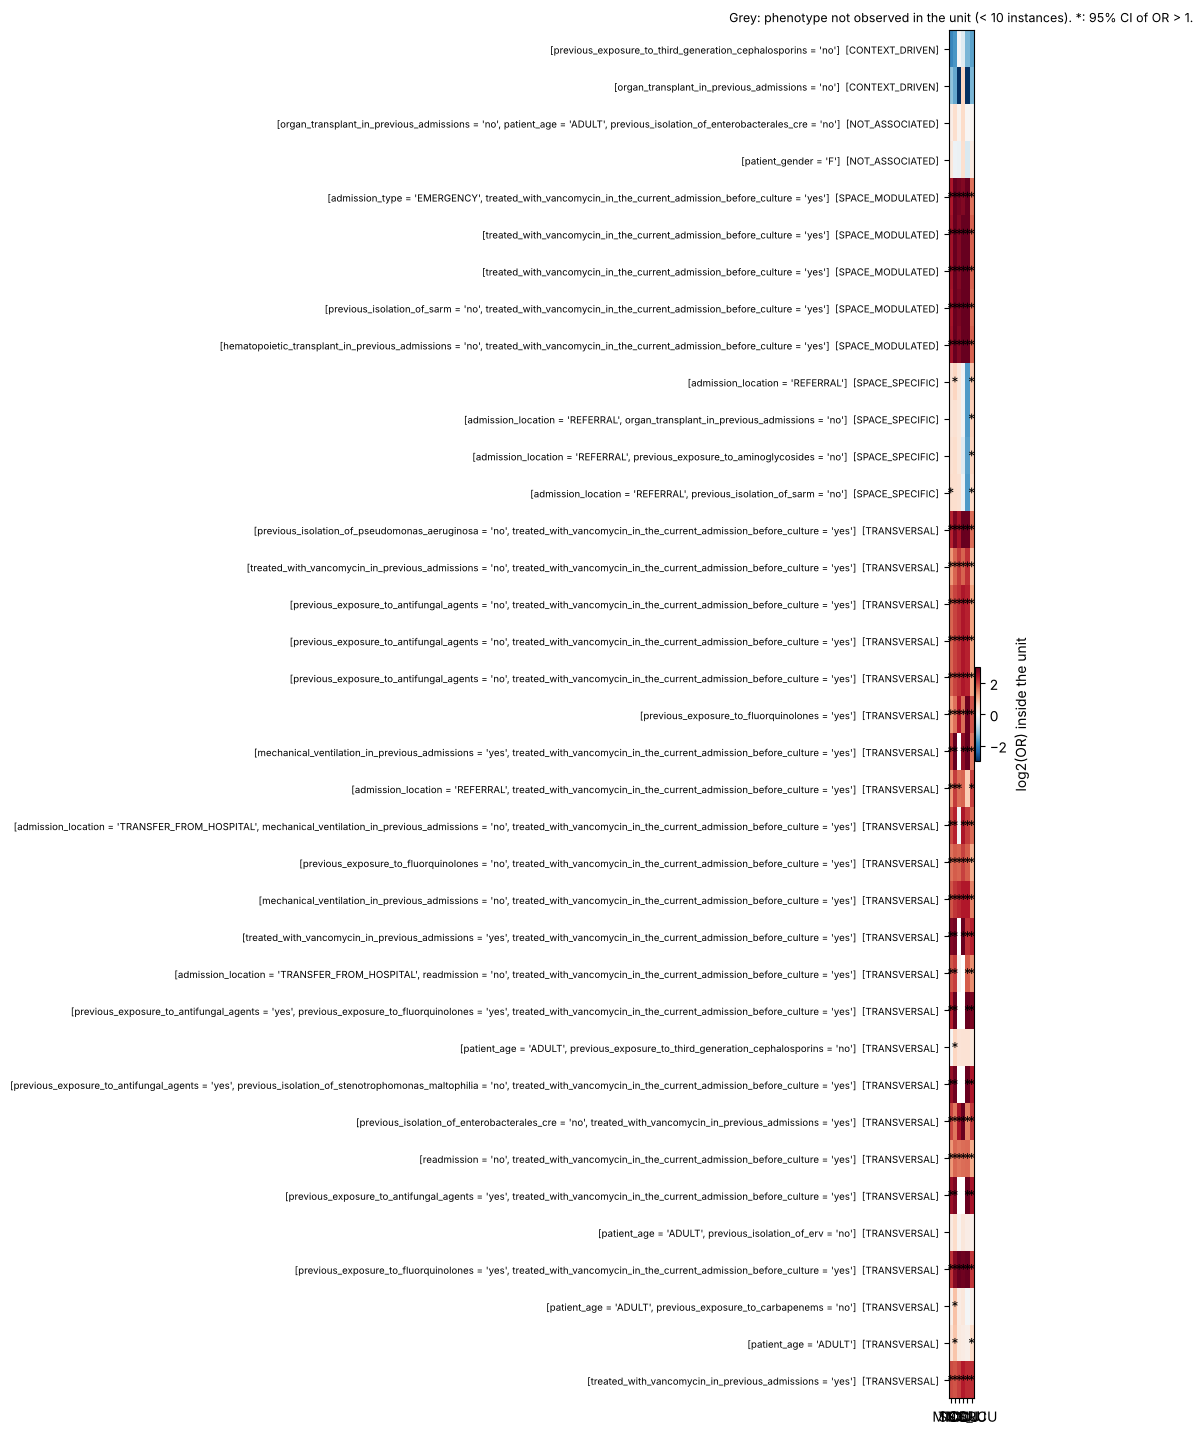

In [6]:
tested = results[results["label_raw"] == "TESTED"].copy()
tested = tested.sort_values(["label", "i2"], ascending=[True, False])
matrix = np.log2(tested[["or_" + u for u in utils.UNITS]].astype(float).values)
labels = [d + "  [" + l + "]" for d, l in zip(tested["patient_description"], tested["label"])]
fig, ax = plt.subplots(figsize=(10, 0.35 * len(tested) + 1.5))
image = ax.imshow(np.ma.masked_invalid(matrix), cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
ax.set_xticks(range(len(utils.UNITS)))
ax.set_xticklabels(utils.UNITS, fontsize=10)
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels, fontsize=7)
for i, (_, row) in enumerate(tested.iterrows()):
    for j, unit in enumerate(utils.UNITS):
        if row.get("or_low_" + unit, 0) > 1:
            ax.text(j, i, "*", ha="center", va="center", fontsize=10)
plt.colorbar(image, ax=ax, label="log2(OR) inside the unit")
ax.set_title("Grey: phenotype not observed in the unit (< 10 instances). *: 95% CI of OR > 1.", fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_PATH / "heatmap_units_phenotypes.pdf")
plt.show()

# 4. Context gain of the phenotypes with context selectors (global configuration with context)

In [7]:
with_context = results[results["context_description"] != "[]"]
context_gain = with_context[["description", "configurations", "precision", "precision_without_context", "precision_gain", "wracc", "wracc_without_context", "context_gain", "label"]].sort_values("precision_gain", ascending=False)
context_gain.to_csv(TABLES_PATH / "context_gain.csv", index=False)
context_gain.round(4)

,description,configurations,precision,precision_without_context,precision_gain,wracc,wracc_without_context,context_gain,label
19,[previous_exposure_to_third_generation_cephalo...,with_context,0.7671,0.3095,0.4577,0.0127,-0.0198,0.0325,CONTEXT_DRIVEN
24,[organ_transplant_in_previous_admissions = 'no...,with_context,0.7568,0.3226,0.4342,0.0126,-0.0081,0.0206,CONTEXT_DRIVEN
14,"[service_when_culture = 'OMED', treated_with_v...",with_context,0.8421,0.5573,0.2848,0.0116,0.0923,-0.0806,SPACE_MODULATED
23,"[previous_exposure_to_fluorquinolones = 'no', ...",with_context,0.5993,0.5116,0.0878,0.0324,0.0561,-0.0237,TRANSVERSAL
15,"[readmission = 'no', service_when_culture = 'M...",with_context,0.5914,0.5045,0.0869,0.0267,0.0463,-0.0196,TRANSVERSAL
18,[previous_exposure_to_antifungal_agents = 'no'...,with_context,0.6059,0.5199,0.0860,0.0373,0.0644,-0.0271,TRANSVERSAL
16,"[admission_type = 'EMERGENCY', service_when_cu...",with_context,0.6291,0.5646,0.0645,0.0254,0.0881,-0.0627,SPACE_MODULATED
20,[previous_exposure_to_antifungal_agents = 'no'...,with_context,0.5628,0.5199,0.0429,0.0184,0.0644,-0.0460,TRANSVERSAL
25,[previous_isolation_of_pseudomonas_aeruginosa ...,with_context,0.5907,0.5511,0.0396,0.0246,0.0852,-0.0606,TRANSVERSAL


# 5. Phenotypic antibiogram by unit

For each unit, the phenotypes of its per-unit lists: number of instances, resistance rate of the phenotype, resistance rate of the unit (classic antibiogram by unit) and lift. The label comes from the context dependence measure.

In [8]:
rows = []
for unit in utils.UNITS:
    dataset = df[df[utils.UNIT_ATTRIBUTE] == unit].reset_index(drop=True)
    y_unit = utils.get_target_mask(dataset)
    for index, subgroup_list in enumerate(best_subgroup_lists("unit_" + unit)):
        for position, description in enumerate(subgroup_list):
            covered = utils.covers(dataset, description)
            label = results.loc[results["description"] == utils.description_to_str(description), "label"]
            rows.append({"unit" : unit, "unit_rate" : y_unit.mean(), "list" : index + 1, "position" : position + 1,
                         "phenotype" : utils.description_to_str(description), "n" : int(covered.sum()),
                         "phenotype_rate" : y_unit[covered].mean(), "lift" : y_unit[covered].mean() / y_unit.mean(),
                         "label" : label.iloc[0] if len(label) else ""})
phenotypic_antibiogram = pd.DataFrame(rows)
phenotypic_antibiogram.to_csv(TABLES_PATH / "phenotypic_antibiogram.csv", index=False)
phenotypic_antibiogram.round(3)

,unit,unit_rate,list,position,phenotype,n,phenotype_rate,lift,label
0,MICU,0.431,1,1,[treated_with_vancomycin_in_previous_admission...,97,0.804,1.866,TRANSVERSAL
1,MICU,0.431,2,1,[hematopoietic_transplant_in_previous_admissio...,366,0.631,1.465,SPACE_MODULATED
2,MICU,0.431,2,2,[patient_gender = 'F'],377,0.459,1.065,NOT_ASSOCIATED
3,MICU,0.431,3,1,"[previous_isolation_of_sarm = 'no', treated_wi...",356,0.635,1.473,SPACE_MODULATED
4,MICU,0.431,3,2,[patient_age = 'ADULT'],338,0.467,1.085,TRANSVERSAL
5,SICU,0.357,1,1,[treated_with_vancomycin_in_previous_admission...,50,0.760,2.129,TRANSVERSAL
6,SICU,0.357,2,1,"[previous_exposure_to_fluorquinolones = 'yes',...",48,0.750,2.101,TRANSVERSAL
7,SICU,0.357,3,1,[mechanical_ventilation_in_previous_admissions...,29,0.828,2.318,TRANSVERSAL
8,SICU,0.357,3,2,[mechanical_ventilation_in_previous_admissions...,184,0.543,1.522,TRANSVERSAL
9,TSICU,0.218,1,1,[treated_with_vancomycin_in_the_current_admiss...,96,0.406,1.867,SPACE_MODULATED
